# 04 · EMT-TF Expression — Rendeiro 2020 CLL (unconditional final step)

The EMT-TF expression step is unconditional and always the last notebook. Score a mesenchymal-TF
panel widened beyond Snail/Zeb/Twist (FOXC, PRRX), **detection-gated** (only TFs expressed above a
sensible floor are shown), and overlay the most informative early(root)/late(terminus) factors as a
**categorical overlay** of thresholded expressers on a grey manifold (not a continuous single-gene
colormap). VIM is a mesenchymal marker, not a TF, and is excluded. Deliverable: `expression.pdf`.

CLL is a mature-B-cell (lymphoid) malignancy; canonical EMT-TFs are expected to be largely silent, so
the panel is read on whichever factors clear the detection floor. Reads `processed.h5ad`.

In [1]:
import os, sys, glob, warnings; warnings.filterwarnings('ignore')
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
os.makedirs(pth_fig, exist_ok=True)

### Load processed data + pseudotime from signatures
`processed.h5ad` per the §6 I/O; the pseudotime and linear layout are carried from the manifold/signatures
step for the early/late split and consistent orientation.

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
sig = sc.read_h5ad(os.path.join(pth_out, 'signatures.h5ad'))
adata = adata[sig.obs_names].copy()
adata.obs['t'] = sig.obs['t'].values
adata.obsm['X_umap_lin'] = sig.obsm['X_umap_lin']
adata.obsm['X_umap'] = adata.obsm['X_umap_lin']
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('cells:', adata.shape[0], '| pseudotime range', round(t.min(),2), '->', round(t.max(),2))

cells: 18490 | pseudotime range 0.0 -> 6.84


### Detection-gated EMT-TF panel

In [4]:
panel = ['SNAI1','SNAI2','ZEB1','ZEB2','TWIST1','TWIST2','FOXC1','FOXC2','PRRX1','PRRX2']
present = [g for g in panel if g in adata.var_names]
early = tn <= np.quantile(tn, 1/3); late = tn >= np.quantile(tn, 2/3)
X = adata[:,present].X; X = X.toarray() if hasattr(X,'toarray') else np.asarray(X)
rows = []
for j, g in enumerate(present):
    x = X[:,j]; expr = x > 0
    rho, p = spearmanr(tn, x)
    rows.append((g, round(expr.mean(),3), round(x[early].mean(),3), round(x[late].mean(),3), round(rho,3)))
df = pd.DataFrame(rows, columns=['TF','frac_expr','mean_early','mean_late','rho_vs_t'])
df['end'] = np.where(df.mean_early > df.mean_late, 'EARLY(root)', 'LATE(terminus)')
df = df.sort_values('rho_vs_t')
print(df.to_string(index=False))
FLOOR = 0.03
ok = df[df.frac_expr > FLOOR]
print(f'\ndetectable TFs (frac>{FLOOR}): {ok.TF.tolist()}')

   TF  frac_expr  mean_early  mean_late  rho_vs_t            end
PRRX1      0.000       0.000      0.000    -0.013 LATE(terminus)
FOXC1      0.000       0.001      0.000    -0.007    EARLY(root)
 ZEB2      0.122       0.074      0.062     0.001    EARLY(root)
 ZEB1      0.038       0.022      0.018     0.008    EARLY(root)
SNAI1      0.001       0.000      0.000     0.021 LATE(terminus)

detectable TFs (frac>0.03): ['ZEB2', 'ZEB1']


### Select the informative factors and overlay
For a linear trajectory the informative readout is a root-end factor and a terminus factor. Only ZEB2
and ZEB1 clear the detection floor here; we take the detectable TF skewed earliest and the one skewed
latest along pseudotime (ties broken by rho). If both detectable TFs skew the same end, we still show
the two detectable factors and state the trend, rather than a degenerate single-gene colormap.

In [5]:
cand = ok.copy()
if len(cand) >= 2:
    early_tf = cand.sort_values('mean_early', ascending=False).iloc[0]['TF']
    late_tf  = cand.sort_values('mean_late',  ascending=False).iloc[0]['TF']
    if early_tf == late_tf:   # same TF dominant both ends -> fall back to the two most detectable
        two = cand.sort_values('frac_expr', ascending=False).head(2)['TF'].tolist()
        early_tf, late_tf = two[0], two[1]
else:
    early_tf = late_tf = cand.iloc[0]['TF']
pair = [g for g in dict.fromkeys([early_tf, late_tf])]
print('shown factors:', pair)
def _vec(g):
    x = adata[:,g].X; return x.toarray().ravel() if hasattr(x,'toarray') else np.asarray(x).ravel()
thr = {}
for g in pair:
    v = _vec(g); pos = v[v>0]; thr[g] = float(np.quantile(pos, 0.75)) if pos.size else 0.0
sel = {g: _vec(g) > thr[g] for g in pair}
print('overlay thresholds (upper quartile among expressers):', {g: round(thr[g],3) for g in pair},
      '| cells shown:', {g: int(sel[g].sum()) for g in pair})
for g in pair:
    m = sel[g]
    print(f'{g}: {(_vec(g)>0).mean()*100:.1f}% expressing; {int(m.sum())} shown; mean pseudotime of shown = {tn[m.values if hasattr(m,"values") else m].mean():.2f} (all = {tn.mean():.2f})')

shown factors: ['ZEB2', 'ZEB1']
overlay thresholds (upper quartile among expressers): {'ZEB2': 0.647, 'ZEB1': 0.618} | cells shown: {'ZEB2': 564, 'ZEB1': 177}
ZEB2: 12.2% expressing; 564 shown; mean pseudotime of shown = 0.30 (all = 0.49)
ZEB1: 3.8% expressing; 177 shown; mean pseudotime of shown = 0.29 (all = 0.49)


### `expression.pdf` — categorical overlay on grey manifold

saved expression.pdf; shown: {'ZEB2': 'blue', 'ZEB1': 'red'}
note: canonical EMT-TFs are near-silent in this lymphoid malignancy; only ZEB2/ZEB1 clear the floor


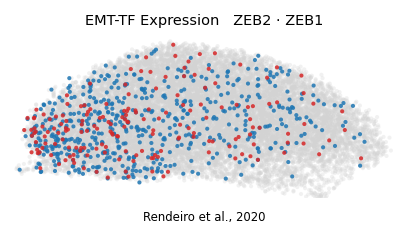

In [6]:
xl = adata.obsm['X_umap']
xlo, xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo, yhi = np.percentile(xl[:,1],[0.3,99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
colors = {pair[0]:'tab:blue'}
if len(pair) > 1: colors[pair[1]] = 'tab:red'
order = sorted(pair, key=lambda g: -int(sel[g].sum()))
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(adata, size=18, alpha=.3, frameon=False, show=False, ax=ax, na_color='lightgray')
for g in order:
    ap = adata[sel[g]].copy()
    sc.pl.umap(ap, na_color=colors[g], size=18, alpha=.85, frameon=False, show=False, ax=ax)
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
if len(pair) > 1:
    lbl = f'EMT-TF Expression   {pair[0]} · {pair[1]}'
else:
    lbl = f'EMT-TF Expression   {pair[0]}'
ax.set_title(lbl, size=7.5)
ax.text(.5, -.14, 'Rendeiro et al., 2020', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'expression.pdf'), bbox_inches='tight'); plt.show()
print('saved expression.pdf; shown:', {g:('blue' if colors[g]=='tab:blue' else 'red') for g in pair})
print('note: canonical EMT-TFs are near-silent in this lymphoid malignancy; only ZEB2/ZEB1 clear the floor')